# Discovering PDEs from Data: Sparse Regression vs Two Neural Networks

Library: `dgs/pde_discovery.py` · Tests: `tests/test_pde_discovery.py` · Uses: NumPy, pandas, PyTorch (GPU if available), SciPy

Given a movie of a field $u(x, t)$, which equation produced it? This notebook answers that question two ways, on data whose true equation we know:

| dataset | true equation | where it comes up |
|---|---|---|
| heat | $u_t = \nu\,u_{xx}$ | diffusion, thermal noise |
| Burgers | $u_t = -u\,u_x + \nu\,u_{xx}$ | nonlinear waves, shocks |
| Schrödinger (harmonic trap) | $\psi_t = \tfrac{i}{2}\psi_{xx} - \tfrac{i}{2}x^2\psi$ | quantum dynamics, qubit control |
| Black–Scholes (call prices) | $V_\tau = \tfrac{\sigma^2}{2}S^2V_{SS} + rSV_S - rV$ | option pricing |

**Route 1, sparse regression** (PDE-FIND, Rudy et al. 2017). Build a library of candidate terms and keep the fewest that reproduce $u_t$. The result is fast and readable, but its derivatives are finite differences.

**Route 2, two networks** (deep hidden physics, Raissi 2018). One network is a smooth prior for the solution $u(x,t)$. A second network models the evolution $u_t = N(u, u_x, u_{xx})$. Both are trained together, so the derivatives come from automatic differentiation. Bahram Jalali's group discusses this two-network idea in its review *Physics-AI symbiosis* (Mach. Learn.: Sci. Technol. 2022, doi:10.1088/2632-2153/ac9215), as a route to automated discovery of governing equations. The same review warns that large networks are **black boxes**. Here the second network's output is turned back into a readable equation by a final sparse fit, so the answer can be checked against physics.

> All data are synthetic, from exact solutions. The Black–Scholes section identifies a PDE from model prices; it is not a trading tool or investment advice.

In [1]:
import sys, pathlib, time, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
from dgs import pde_discovery as P
import torch
OI = dict(blue='#0072B2', orange='#E69F00', green='#009E73', red='#D55E00', sky='#56B4E9', purple='#CC79A7', grey='#888888', ink='#222222')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False, 'axes.spines.right': False})
FIG = ROOT / 'notebooks' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
def save(fig, name): fig.savefig(FIG / f'pde_{name}.png', bbox_inches='tight', dpi=110)
DEV = P.device()
print('torch', torch.__version__, '| device:', DEV, '|', torch.cuda.get_device_name(0) if DEV.type == 'cuda' else 'CPU only')

torch 2.11.0+cu128 | device: cuda | NVIDIA GeForce RTX 4060


## 1. The data

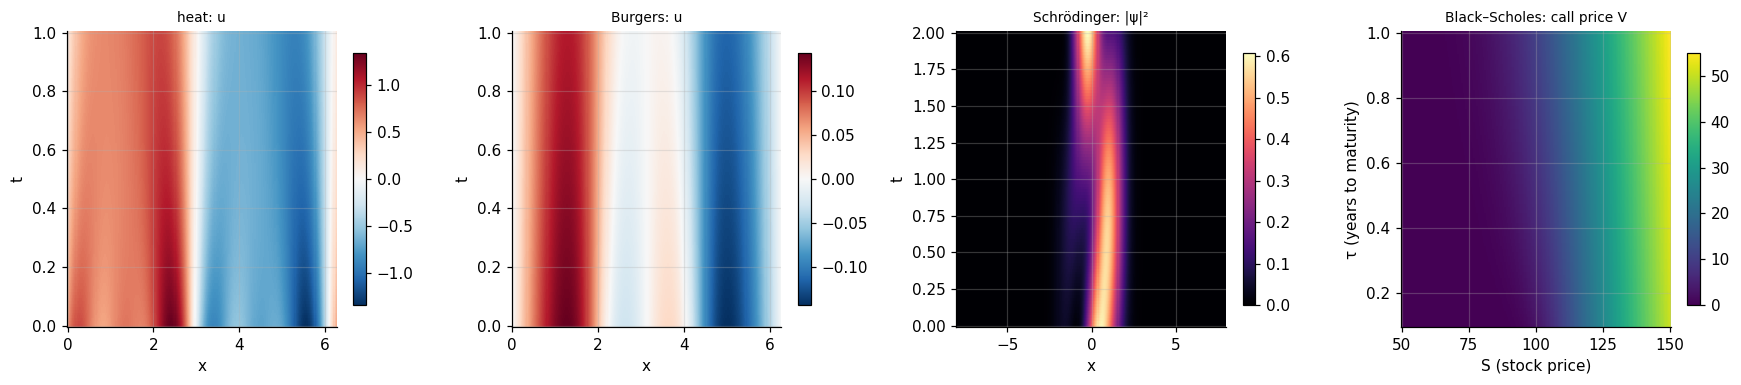

In [2]:
data = {'heat': P.heat(), 'burgers': P.burgers(), 'schrodinger': P.schrodinger(), 'black_scholes': P.black_scholes()}
fig, axs = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (name, d) in zip(axs, data.items()):
    z = np.abs(d['u']) ** 2 if np.iscomplexobj(d['u']) else d['u']
    im = ax.pcolormesh(d['x'], d['t'], z, cmap='magma' if name == 'schrodinger' else 'RdBu_r' if name != 'black_scholes' else 'viridis', shading='auto')
    fig.colorbar(im, ax=ax, shrink=0.85)
    ax.set_title({'heat': 'heat: u', 'burgers': 'Burgers: u', 'schrodinger': 'Schrödinger: |ψ|²', 'black_scholes': 'Black–Scholes: call price V'}[name], fontsize=9)
    ax.set_xlabel('S (stock price)' if name == 'black_scholes' else 'x'); ax.set_ylabel('τ (years to maturity)' if name == 'black_scholes' else 't')
fig.tight_layout(); save(fig, 'data'); plt.show()

*Figure 1.* The four datasets. Heat: three sine modes decaying at rates $\nu k^2$, so the fine ripples fade first. Burgers: the exact Cole–Hopf solution, a wave shaped by nonlinear steepening and viscous smoothing that slowly decays. Schrödinger: probability density of a superposition of the three lowest harmonic-oscillator states, sloshing back and forth in the trap. Black–Scholes: European call prices against stock price and time to maturity, near zero well below the strike of 100 and rising steadily above it.

## 2. Route 1: sparse regression on clean data

Each candidate term is weighted, and terms contributing less than a threshold are dropped. The threshold is swept, and the **fewest-term model whose residual is within 25 % of the best** is kept: the knee of the accuracy-against-complexity curve.

In [3]:
rows = []
for name, d in data.items():
    found = P.discover(d, 'finance' if name == 'black_scholes' else 'standard')
    t = P.as_table(found, d['truth']); t.insert(0, 'dataset', name); rows.append(t)
    e = P.coefficient_error(found, d['truth'])
    print(f"{name:14s} terms exact: {e['exact_terms']}, worst coefficient error {e['max_rel_err']:.1e}")
table = pd.concat(rows, ignore_index=True)
fmt = lambda v: f'{v.real:+.5f}' if abs(v.imag) < 1e-9 else f'{v.real:+.5f}{v.imag:+.5f}i'
print(); print(table.to_string(index=False, formatters={'discovered': fmt, 'true': fmt}))

heat           terms exact: True, worst coefficient error 4.8e-05
burgers        terms exact: True, worst coefficient error 3.8e-06
schrodinger    terms exact: True, worst coefficient error 2.8e-04
black_scholes  terms exact: True, worst coefficient error 4.0e-03

      dataset     term        discovered              true
         heat     u_xx          +0.10000          +0.10000
      burgers    u*u_x          -1.00000          -1.00000
      burgers     u_xx          +0.10000          +0.10000
  schrodinger     u_xx +0.00001+0.49988i +0.00000+0.50000i
  schrodinger    x^2*u +0.00001-0.49986i -0.00000-0.50000i
black_scholes    S*u_S          +0.04993          +0.05000
black_scholes S^2*u_SS          +0.02002          +0.02000
black_scholes        u          -0.04980          -0.05000


All four equations come back with exactly the right terms, from libraries of 7 to 9 candidates:
* the heat diffusivity and both Burgers coefficients, to parts in 10⁵;
* the Schrödinger equation's $\tfrac{i}{2}\psi_{xx} - \tfrac{i}{2}x^2\psi$, to 3 parts in 10⁴;
* the Black–Scholes terms, to 0.4 %.

From the Black–Scholes coefficients you can read the **implied volatility**, $\sigma = \sqrt{2\times\text{coefficient of }S^2V_{SS}} \approx 0.200$, and the **interest rate** $r \approx 0.0499$ (true values 0.2 and 0.05).

The Schrödinger result passes a quantum consistency check. Both coefficients are **purely imaginary**, so the discovered generator is anti-Hermitian and the evolution is unitary: total probability is conserved. A discovered equation that broke this would be physically wrong even if it fit the data.

In [4]:
d = data['schrodinger']; dx = d['x'][1] - d['x'][0]
norm = np.sum(np.abs(d['u']) ** 2, axis=1) * dx
found = P.discover(d)
print('probability over time: min %.6f, max %.6f' % (norm.min(), norm.max()))
print('largest real part / magnitude of discovered coefficients: %.1e' % max(abs(c.real) / abs(c) for c in found.values()))
bs = P.discover(data['black_scholes'], 'finance')
print(f"implied sigma = {np.sqrt(2 * bs['S^2*u_SS']):.4f},  implied r = {bs['S*u_S']:.4f} (from S V_S) and {-bs['u']:.4f} (from V)")

probability over time: min 1.000000, max 1.000000
largest real part / magnitude of discovered coefficients: 2.3e-05
implied sigma = 0.2001,  implied r = 0.0499 (from S V_S) and 0.0498 (from V)


## 3. Noise breaks finite differences

Real measurements are noisy. A second derivative by finite differences multiplies noise by about $1/\Delta x^2$, so even tiny noise swamps $u_{xx}$.

heat     noise   0e+00: terms ['u_xx']  worst coefficient error 4.80e-05
heat     noise   1e-05: terms ['u_xx']  worst coefficient error 2.77e-04
heat     noise   1e-04: terms ['u_xx']  worst coefficient error 3.25e-02


heat     noise   1e-03: terms ['u']  worst coefficient error 1.00e+00


heat     noise   1e-02: terms ['u']  worst coefficient error 1.00e+00
burgers  noise   0e+00: terms ['u*u_x', 'u_xx']  worst coefficient error 3.80e-06
burgers  noise   1e-05: terms ['u*u_x', 'u_xx']  worst coefficient error 7.27e-04


burgers  noise   1e-04: terms ['u*u_x', 'u_xx']  worst coefficient error 6.81e-02
burgers  noise   1e-03: terms ['u']  worst coefficient error 1.00e+00


burgers  noise   1e-02: terms ['u']  worst coefficient error 1.00e+00


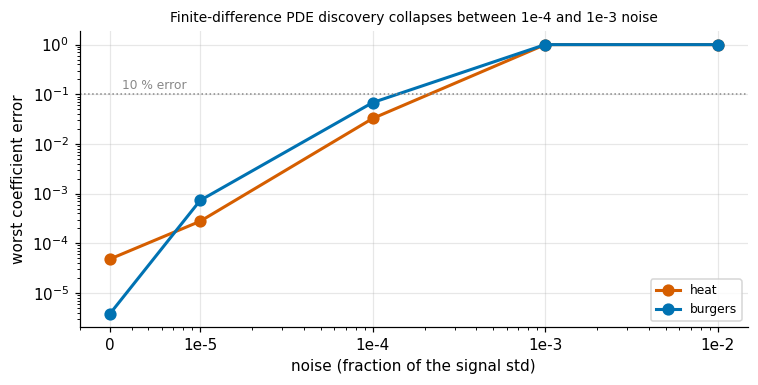

In [5]:
levels = [0, 1e-5, 1e-4, 1e-3, 1e-2]
res = {}
for name in ('heat', 'burgers'):
    d = data[name]; res[name] = []
    for lv in levels:
        f = P.discover(P.add_noise(d, lv, seed=1) if lv else d)
        e = P.coefficient_error(f, d['truth']); res[name].append(e['max_rel_err'])
        print(f"{name:8s} noise {lv:7.0e}: terms {sorted(f)}  worst coefficient error {e['max_rel_err']:.2e}")
fig, ax = plt.subplots(figsize=(7, 3.6))
for name, col in (('heat', OI['red']), ('burgers', OI['blue'])):
    ax.loglog([max(l, 3e-6) for l in levels], np.maximum(res[name], 1e-6), 'o-', color=col, lw=2, ms=7, label=name)
ax.axhline(0.1, color=OI['grey'], ls=':', lw=1); ax.text(3.5e-6, 0.13, '10 % error', fontsize=8, color=OI['grey'])
ax.set_xticks([3e-6, 1e-5, 1e-4, 1e-3, 1e-2], ['0', '1e-5', '1e-4', '1e-3', '1e-2'])
ax.set_xlabel('noise (fraction of the signal std)'); ax.set_ylabel('worst coefficient error'); ax.legend(fontsize=8)
ax.set_title('Finite-difference PDE discovery collapses between 1e-4 and 1e-3 noise', fontsize=9)
fig.tight_layout(); save(fig, 'noise'); plt.show()

*Figure 2.* Worst coefficient error of the finite-difference route against noise level, for heat (red) and Burgers (blue). The leftmost points are noise-free, plotted at the left edge. Clean data give errors of 10⁻⁵ or less, and the errors grow about tenfold for every tenfold increase in noise. At 10⁻⁴ noise the coefficients are off by 3–7 %. By 10⁻³, the spectral second derivative is dominated by amplified noise and the method picks the wrong terms: an error of 1 means a true term was dropped entirely. At 1 % noise both equations are lost. The printout lists the terms chosen at each level.

## 4. Route 2: two networks on 1 % noisy data

The prior network $u_{\text{net}}(x,t)$ (4 hidden layers × 48, tanh) fits the noisy samples. The dynamics network $N_{\text{net}}(u, u_x, u_{xx})$ (2 × 32) must match $\partial_t u_{\text{net}}$. Both are trained together with Adam on 6000 random samples. Afterwards, a sparse fit to the prior's autograd derivatives turns the black-box $N_{\text{net}}$ into a readable equation.

heat      44.1 s on cuda: {u_xx: +0.0955}  terms exact True, worst error 0.045; black box N_net residual 0.014


burgers   38.0 s on cuda: {u_xx: +0.0991, u*u_x: -0.9930}  terms exact True, worst error 0.009; black box N_net residual 0.006


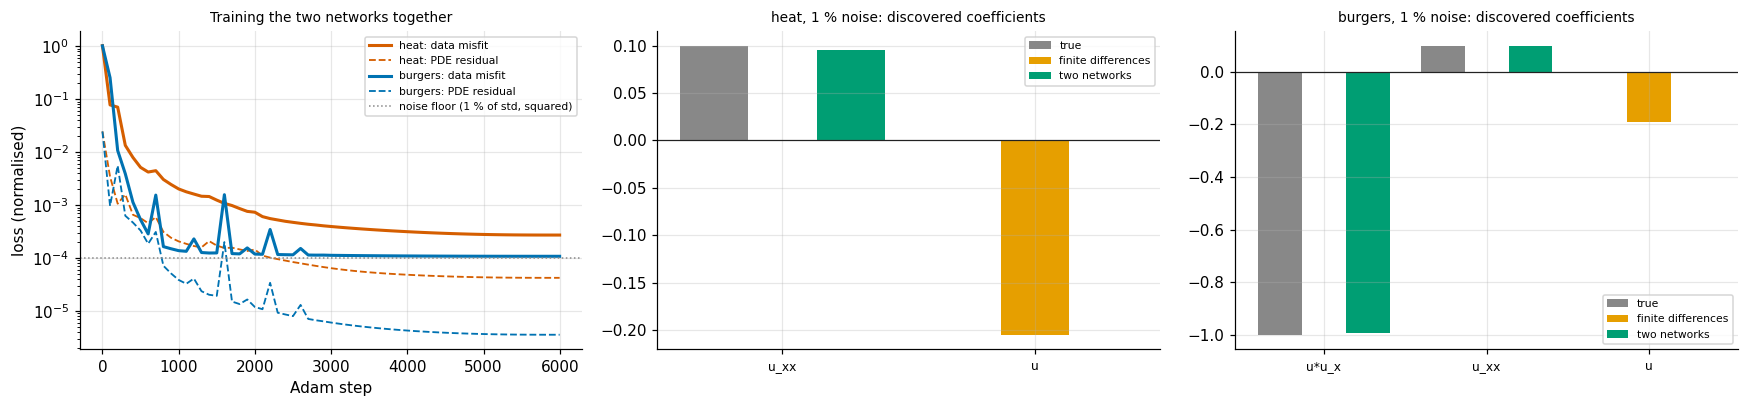

In [6]:
nets, two_net = {}, {}
for name in ('heat', 'burgers'):
    d = data[name]; dn = P.add_noise(d, 0.01, seed=1)
    t0 = time.time()
    m = P.HiddenPhysics(dev=DEV).fit(dn, n_points=6000, steps=6000, lr=2e-3, log_every=100)
    nets[name] = m; two_net[name] = m.discover(d)
    e = P.coefficient_error(two_net[name], d['truth'])
    print(f"{name:8s} {time.time()-t0:5.1f} s on {DEV}: {{{', '.join(f'{k}: {v:+.4f}' for k, v in two_net[name].items())}}}  "
          f"terms exact {e['exact_terms']}, worst error {e['max_rel_err']:.3f}; black box N_net residual {m.black_box_residual(d):.3f}")
fig, axs = plt.subplots(1, 3, figsize=(16, 3.8))
for name, col in (('heat', OI['red']), ('burgers', OI['blue'])):
    h = np.array(nets[name].history)
    axs[0].semilogy(h[:, 0], h[:, 1], color=col, lw=2, label=f'{name}: data misfit')
    axs[0].semilogy(h[:, 0], h[:, 2], color=col, lw=1.2, ls='--', label=f'{name}: PDE residual')
axs[0].axhline(1e-4, color=OI['grey'], ls=':', lw=1, label='noise floor (1 % of std, squared)')
axs[0].set_xlabel('Adam step'); axs[0].set_ylabel('loss (normalised)'); axs[0].legend(fontsize=7); axs[0].set_title('Training the two networks together', fontsize=9)
for ax, name in zip(axs[1:], ('heat', 'burgers')):
    d = data[name]; fd = P.discover(P.add_noise(d, 0.01, seed=1))
    terms = sorted(set(d['truth']) | set(fd) | set(two_net[name]), key=lambda k: (k not in d['truth'], k))
    xk = np.arange(len(terms)); w = 0.27
    ax.bar(xk - w, [d['truth'].get(k, 0) for k in terms], w, color=OI['grey'], label='true')
    ax.bar(xk, [fd.get(k, 0) for k in terms], w, color=OI['orange'], label='finite differences')
    ax.bar(xk + w, [two_net[name].get(k, 0) for k in terms], w, color=OI['green'], label='two networks')
    ax.set_xticks(xk, terms, fontsize=8); ax.axhline(0, color=OI['ink'], lw=0.8); ax.legend(fontsize=7)
    ax.set_title(f'{name}, 1 % noise: discovered coefficients', fontsize=9)
fig.tight_layout(); save(fig, 'two_networks'); plt.show()

*Figure 3.* Left: training history. Solid lines are the data misfit. For Burgers it levels off at the noise floor (dotted): the prior fits the signal, not the noise. For heat it stays about 2.5 times above the floor, so its prior is less complete. Dashed lines are the PDE residual, how well the dynamics network explains the prior's time derivative. Middle and right: coefficients from 1 %-noise data. Grey is the truth; orange is finite differences, which pick a spurious term $u$ and miss the physics entirely; green is the two-network route, which returns exactly the right terms. In this run the Burgers coefficients are within 1 %, and the heat diffusivity within about 5 %: its fast mode decays quickly, so it is a small, fading part of the signal. The exact numbers are in the printout; they vary a little with the random seed. The smooth network prior is what makes derivatives of noisy data usable.

## 5. The parsimony knee

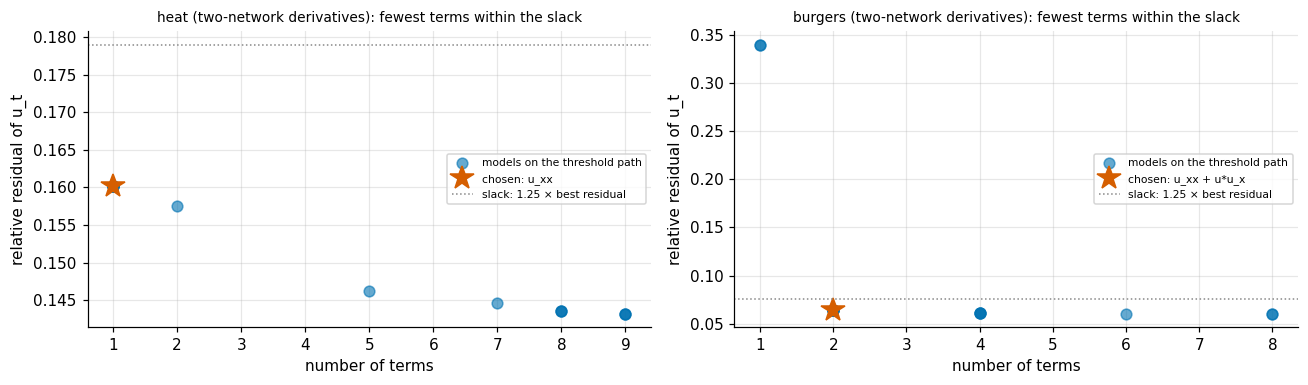

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, name in zip(axs, ('heat', 'burgers')):
    D = nets[name].derivative_fields(data[name]); lib = P.standard_library(D)
    chosen, path = P.stridge_path(lib, D['u_t'])
    n = np.array([p[1] for p in path]); r = np.array([p[2] for p in path])
    ax.plot(n, r, 'o', color=OI['blue'], ms=7, alpha=0.6, label='models on the threshold path')
    ax.plot(len(chosen), P.residual(lib, D['u_t'], chosen), '*', color=OI['red'], ms=16, label='chosen: ' + ' + '.join(chosen))
    ax.axhline(1.25 * r.min(), color=OI['grey'], ls=':', lw=1, label='slack: 1.25 × best residual')
    ax.set_xlabel('number of terms'); ax.set_ylabel('relative residual of u_t'); ax.legend(fontsize=7, loc='center right')
    ax.set_title(f'{name} (two-network derivatives): fewest terms within the slack', fontsize=9)
fig.tight_layout(); save(fig, 'knee'); plt.show()

*Figure 4.* Each dot is the model found at one threshold: its number of terms against how much of $u_t$ it leaves unexplained. Adding terms always lowers the residual a little, because extra terms fit derivative errors. The rule keeps the **fewest** terms whose residual is within 25 % of the best (dotted line); the red star is the model chosen. This is the "simplest equation that explains the data" principle, made into an explicit, repeatable rule rather than a judgment call.

## 6. CPU or GPU

In [8]:
def time_steps(dev, steps=300):
    m = P.HiddenPhysics(dev=dev)
    t0 = time.time(); m.fit(P.add_noise(data['burgers'], 0.01), n_points=6000, steps=steps)
    if dev.type == 'cuda': torch.cuda.synchronize()
    return (time.time() - t0) / steps * 1e3
cpu_ms = time_steps(torch.device('cpu'))
print(f'CPU: {cpu_ms:.1f} ms per training step (6000 points, second derivatives by autograd)')
if torch.cuda.is_available():
    gpu_ms = time_steps(torch.device('cuda'))
    print(f'GPU ({torch.cuda.get_device_name(0)}): {gpu_ms:.1f} ms per step  ->  {cpu_ms / gpu_ms:.1f}x faster')
else:
    print('no CUDA GPU visible: everything above ran on the CPU')

CPU: 15.3 ms per training step (6000 points, second derivatives by autograd)


GPU (NVIDIA GeForce RTX 4060): 11.4 ms per step  ->  1.3x faster


## 7. Package the datasets for Kaggle

`kaggle_package` writes one CSV per dataset (long format: x, t, u, or real and imaginary parts for ψ), a README data card listing each true equation, and the `dataset-metadata.json` that the Kaggle command-line tool reads. Nothing is uploaded. To publish, put your Kaggle username in the metadata and run `kaggle datasets create -p notebooks/kaggle_pde_discovery`. The folder is git-ignored.

In [9]:
small = {'heat': P.heat(nx=128, nt=51), 'burgers': P.burgers(nx=128, nt=51), 'schrodinger': P.schrodinger(nx=128, nt=51),
         'black_scholes': P.black_scholes(nS=101, nt=46), 'burgers_noise_1pct': P.add_noise(P.burgers(nx=128, nt=51), 0.01, seed=7)}
out = P.kaggle_package(ROOT / 'notebooks' / 'kaggle_pde_discovery', small)
for f in sorted(out.iterdir()):
    print(f'{f.name:28s} {f.stat().st_size/1024:8.1f} kB')
print(json.dumps(json.loads((out / 'dataset-metadata.json').read_text())['resources'][:2], indent=1))
print(pd.read_csv(out / 'schrodinger.csv').head(3).to_string(index=False))

black_scholes.csv                99.5 kB
burgers.csv                     203.4 kB
burgers_noise_1pct.csv          204.0 kB
dataset-metadata.json             0.7 kB
heat.csv                        197.9 kB
README.md                         0.6 kB
schrodinger.csv                 265.5 kB
[
 {
  "path": "heat.csv",
  "description": "u_t = 0.1 u_xx"
 },
 {
  "path": "burgers.csv",
  "description": "u_t = -1 u*u_x + 0.1 u_xx"
 }
]
     x   t        u_real       u_imag
-8.000 0.0 -4.622567e-14 2.820530e-13
-7.875 0.0 -1.224076e-13 7.369602e-13
-7.750 0.0 -3.190057e-13 1.894730e-12


## 8. Limitations
* 1-D problems with exact, uniformly sampled data. Real data bring irregular sampling, boundaries and unknown noise.
* The library has to contain the true terms. Sparse regression cannot discover a term nobody thought to include.
* The two-network fit is a non-convex optimisation. Results vary a little with the random seed and the training length; the tests use loose bounds for that reason.
* The 25 % parsimony slack is a choice. Stricter or looser values trade missed terms against spurious ones.
* Black–Scholes prices are model output. Identifying the model from its own prices is an exercise in method, not evidence about markets.